## Problem 1: Visualise data in an interactive map (10 points)


Create an *interactive* **thematic map** using the skills you learnt during lesson 5. You can use *Folium*,<br>
or any other suitable Python package - feel free to experiment).

The map should contain more than one layer (from at least two different data sets). Pay attention to <br>
classification and visualisation (appropriate colour scheme choice, etc.). Write your code in this <br>
notebook, and store the resulting maps in `.html` format (plus possibly additional files, depending on<br>
your approach) in the `NOTEBOOK_DIRECTORY / "docs"` folder.

### Topic of the map

- Use any of the data sets we have used during the course (travel time data, population grid), or <br>
  any other data set of your interest (for example, [open data sets from Statistics Finland](https://www.stat.fi/org/avoindata/index_en.html), <br>
  or the open geo-data from [the Helsinki Region Infoshare](https://hri.fi/en)). If you download <br>
  data sets, add, commit, and push them to the `DATA_DIRECTORY`. Be sure to include an attribution <br>
  to each data set in your output map!
- Feel free to start from and adapt examples from the course material! You can take one step further <br>
  and add additional analysis to, e.g., the shopping centre dominance or the population within vincinity <br>
  of certain addresses)
- This should **not** be an interactive version of your submission for *problem 1*! Create something new!

### Criteria

- The map has more than one data layer (for instance, the results of an analysis, and the road network <br>
  to illustrate a complex spatial pattern). If (and only if) you think it adds additional value, feel <br>
  free to add a base map (but a base map does not count as an own layer)
- The map portrays the output of an analysis or a classification that adds value beyond just displaying <br>
  the raw data
- The map follows good cartographic practices (appropriate map extent and zoom level, colour scheme, <br>
  legend and data sources, etc.)
- The map demonstrates the skills learnt during lesson 5, interactive elements (popups, etc.) are a plus.

### Output

- Save the map(s) in `.png` format in the `NOTEBOOK_DIRECTORY / "docs"` folder, remember to add, commit, <br>
  and push them to the GitHub repository
- Remember to also add, commit, and push input data sets and code

---

In [2]:
import pathlib 
NOTEBOOK_PATH = pathlib.Path().resolve()
DATA_DIRECTORY = NOTEBOOK_PATH / "data"
OUTPUT_DIRECTORY = NOTEBOOK_PATH / "docs"

In [3]:
# ADD YOUR OWN CODE HERE

In [4]:
# Most necessary imports
import json
import os
import geopandas as gpd
import pandas as pd
# import requests
# from datetime import datetime
import matplotlib.pyplot as plt
# import contextily as cx
import networkx as nx
import osmnx as ox

os.environ['PROJ_LIB'] = '/path/to/env/share/proj'
#os.environ['GDAL_DATA'] = '/path/to/env/share/'

,geometry,bbox_north,bbox_south,bbox_east,bbox_west,place_id,osm_type,osm_id,lat,lon,display_name,class,type,importance
0,"POLYGON ((24.78280 60.09996, 24.81697 60.06209...",60.29785,59.922486,25.254512,24.782803,307466317,relation,34914,60.167488,24.942747,"Helsinki, Helsinki sub-region, Uusimaa, Southe...",boundary,administrative,0.9585


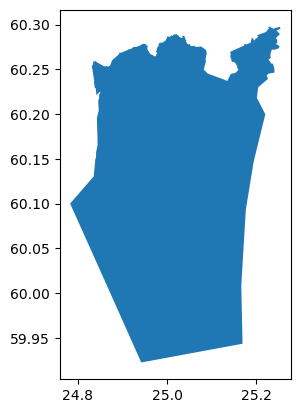

In [7]:
area = ox.geocode_to_gdf("Helsinki, Finland")
area.plot()
area.head()

In [5]:
print(ox.settings.useful_tags_way)

['bridge', 'tunnel', 'oneway', 'lanes', 'ref', 'name', 'highway', 'maxspeed', 'service', 'access', 'area', 'landuse', 'width', 'est_width', 'junction']


In [5]:
ox.settings.useful_tags_way = ox.settings.useful_tags_way + ['cycleway:right', 'bicycle', 'route']

In [8]:
print(area.iloc[0])

geometry        POLYGON ((24.7828026 60.0999604, 24.816973 60....
bbox_north                                               60.29785
bbox_south                                              59.922486
bbox_east                                               25.254512
bbox_west                                               24.782803
place_id                                                307466317
osm_type                                                 relation
osm_id                                                      34914
lat                                                     60.167488
lon                                                     24.942747
display_name    Helsinki, Helsinki sub-region, Uusimaa, Southe...
class                                                    boundary
type                                               administrative
importance                                                 0.9585
Name: 0, dtype: object


road_network = ox.geometries_from_polygon(area.iloc[0].geometry, tags={'highway': 'cycleway|path|'})
road_network.plot()

In [9]:
G_all = ox.graph_from_place("Helsinki, Finland", network_type='all')

In [11]:
_, gdf_edges_all = ox.graph_to_gdfs(G_all)
#_, gdf_edges_bike_l = ox.graph_to_gdfs(G_bike_lanes)
gdf_edges_all = gdf_edges_all.reset_index()
gdf_edges_all.head()
#gdf_edges_bike_l.explore(m=m)
#gdf_cycle_net = gdf_edges[gdf_edges['highway'] == 'cycleway']

,u,v,key,osmid,oneway,lanes,name,highway,maxspeed,bicycle,...,bridge,ref,junction,cycleway:right,access,service,width,tunnel,est_width,area
0,131941,269328887,0,"[264473404, 179043485, 24787814]",True,"[1, 2]",Kuusisaarentie,secondary,50,use_sidepath,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,131941,922854269,0,"[81178546, 78722622]",False,2,Kuusisaarentie,secondary,50,use_sidepath,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,131979,25279537,0,155797293,False,2,Kuusisaarenpolku,residential,30,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,131979,286092631,0,"[76737123, 301517769, 18467132, 179043484, 184...",False,2,Kuusisaarentie,secondary,50,use_sidepath,...,yes,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,131979,29416840,0,85564173,False,2,Kuusisaarentie,secondary,50,use_sidepath,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
gdf_bicycle_designated = gdf_edges_all[gdf_edges_all['bicycle'] == 'designated']
print(gdf_bicycle_designated[['osmid', 'highway', 'bicycle', 'cycleway:right']].info())
gdf_cycleway = gdf_edges_all[gdf_edges_all['highway'] == 'cycleway']
print(gdf_cycleway[['osmid', 'highway', 'bicycle', 'cycleway:right']].info())
gdf_cyclelane = gdf_edges_all[gdf_edges_all['cycleway:right'].isin(['lane', 'shared_lane'])]
print(gdf_cyclelane[['osmid', 'highway', 'bicycle', 'cycleway:right']].info())

NameError: name 'gdf_edges_all' is not defined

<AxesSubplot: >

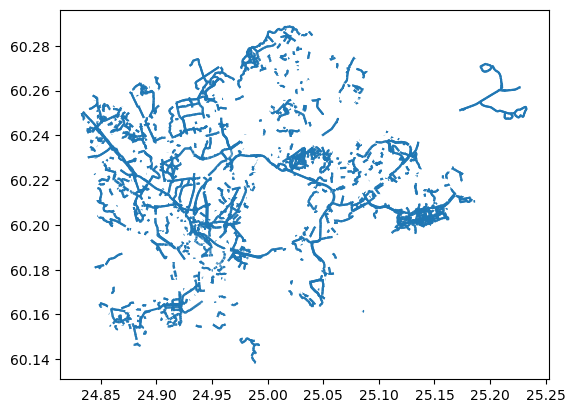

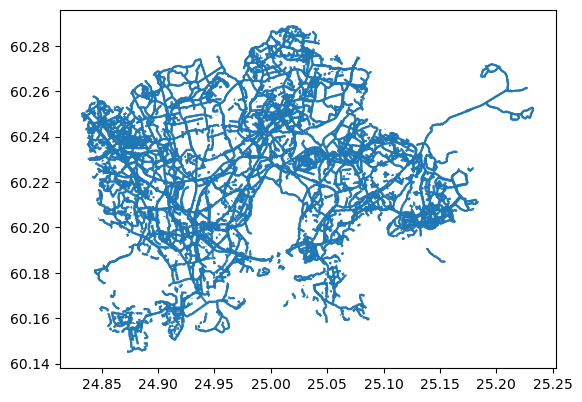

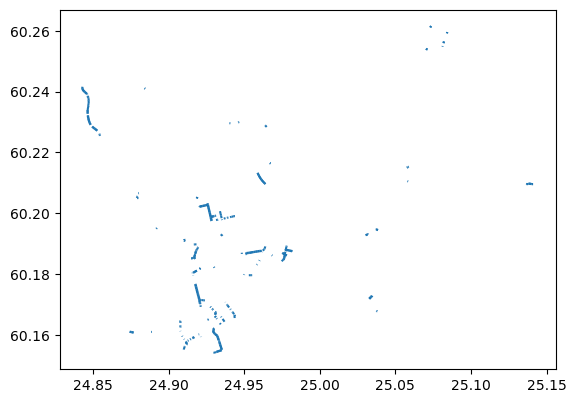

In [27]:
gdf_bicycle_designated.plot()
gdf_cycleway.plot()
gdf_cyclelane.plot()

from pyrosm import OSM
from pyrosm import get_data
fp = get_data('Helsinki', directory=DATA_DIRECTORY)
osm = OSM(fp)

cycle_net = osm.get_network(network_type='cycling')
cycle_net.head()

In [31]:
gdfs = [gdf_bicycle_designated, gdf_cycleway, gdf_cyclelane]
ind = None
for g in gdfs:
    if ind is None:
        ind = g.index
    else:
        ind = ind.union(g.index)
cycle_net = gdf_edges_all.loc[ind]
print(cycle_net.info())
cycle_net.explore()

<class 'geopandas.geodataframe.GeoDataFrame'>
Int64Index: 68043 entries, 21 to 424733
Data columns (total 23 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   u               68043 non-null  int64   
 1   v               68043 non-null  int64   
 2   key             68043 non-null  int64   
 3   osmid           68043 non-null  object  
 4   oneway          68043 non-null  bool    
 5   lanes           2069 non-null   object  
 6   name            12789 non-null  object  
 7   highway         68043 non-null  object  
 8   maxspeed        1366 non-null   object  
 9   bicycle         27524 non-null  object  
 10  reversed        68043 non-null  object  
 11  length          68043 non-null  float64 
 12  geometry        68043 non-null  geometry
 13  bridge          967 non-null    object  
 14  ref             12 non-null     object  
 15  junction        23 non-null     object  
 16  cycleway:right  710 non-null    object  
 17  ac

In [ ]:
gdf_edges_all.explore()